In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

In [100]:
df = pd.read_csv("Iris.csv")

In [101]:
print("Number of Samples  :", df.shape[0])
print("Number of features :", df.shape[1])

Number of Samples  : 150
Number of features : 6


In [102]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [103]:
print("Features Name :")
print(df.columns.tolist())

print("\nDataset Information :")
print(df.info())
print("\nStatistical Summary :")
display(df.describe(include='all'))

Features Name :
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

Dataset Information :
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB
None

Statistical Summary :


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
count,150.000000,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,NaN,50
mean,75.500000,5.843333,3.054000,3.758667,1.198667,NaN
std,43.445368,0.828066,0.433594,1.764420,0.763161,NaN
min,1.000000,4.300000,2.000000,1.000000,0.100000,NaN
25%,38.250000,5.100000,2.800000,1.600000,0.300000,NaN
50%,75.500000,5.800000,3.000000,4.350000,1.300000,NaN
75%,112.750000,6.400000,3.300000,5.100000,1.800000,NaN


In [104]:
print(df.isnull().sum())

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [105]:
# Feature_column = df.drop(columns=["Id", "Species"])
Feature_column = [
    'SepalLengthCm',
    'SepalWidthCm',
    'PetalLengthCm',
    'PetalWidthCm',
]
scaler = StandardScaler()
X = df[Feature_column].copy()
display(X.head())
X_scaled = scaler.fit_transform(X)
print("Scaled Features Matrix Shape : ", X_scaled.shape)

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Scaled Features Matrix Shape :  (150, 4)


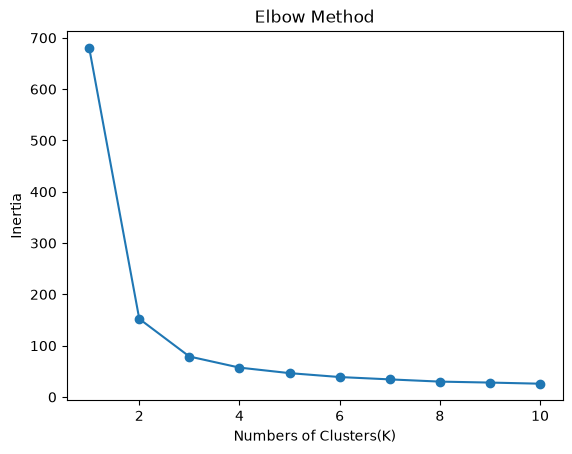

In [106]:
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Numbers of Clusters(K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [107]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X)
df_result = df.copy()
df_result["KMeans_clustors"] = km_labels
print(df_result["KMeans_clustors"].value_counts())

KMeans_clustors
0    62
1    50
2    38
Name: count, dtype: int64


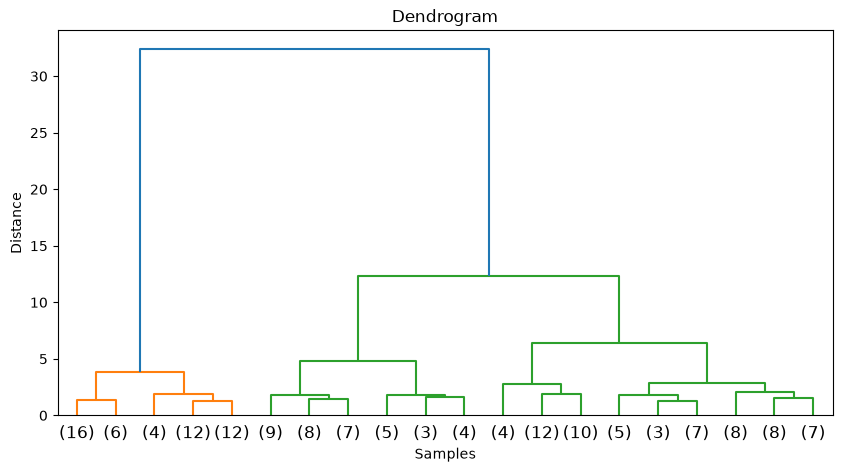

In [108]:
Z = linkage(X, method="ward")
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.title("Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()

In [109]:
hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_labels = hc.fit_predict(X)

df_result["Hierarchical_clusters"] = hc_labels
print(df_result["Hierarchical_clusters"].value_counts())

Hierarchical_clusters
0    64
1    50
2    36
Name: count, dtype: int64


In [110]:
print("Average of each feature in every K-Means cluster:")

numeric_cols = df.select_dtypes(include="number").columns

print(
    df_result.groupby("KMeans_clustors")[numeric_cols]
    .mean()
    .round(2)
)

Average of each feature in every K-Means cluster:
                     Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  \
KMeans_clustors                                                       
0                 87.35           5.90          2.75           4.39   
1                 25.50           5.01          3.42           1.46   
2                121.95           6.85          3.07           5.74   

                 PetalWidthCm  
KMeans_clustors                
0                        1.43  
1                        0.24  
2                        2.07  


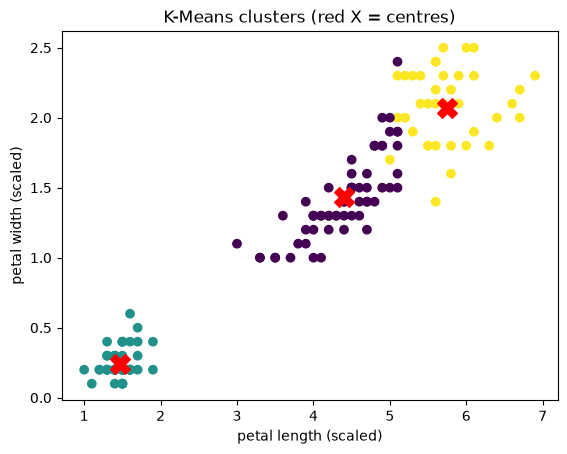

In [111]:
# Plot the data points
plt.scatter(X.iloc[:, 2], X.iloc[:, 3], c=km_labels)

# Plot the cluster centres
plt.scatter(
    kmeans.cluster_centers_[:, 2],
    kmeans.cluster_centers_[:, 3],
    c="red",
    marker="X",
    s=200
)

plt.xlabel("petal length (scaled)")
plt.ylabel("petal width (scaled)")
plt.title("K-Means clusters (red X = centres)")
plt.show()

In [112]:
true_labels = df["Species"]
print(pd.crosstab(true_labels, km_labels, rownames=["Species"], colnames=["KMean Clusters"]))

KMean Clusters    0   1   2
Species                    
Iris-setosa       0  50   0
Iris-versicolor  48   0   2
Iris-virginica   14   0  36
